# ASSIGNMENT No: 09
## Implement Agglomerative Hierarchical Clustering Algorithm

**Dataset:** Credit Card Dataset (`CC_GENERAL.csv`)

**Objective:** Implement Agglomerative Hierarchical Clustering, visualize the hierarchy using a dendrogram, compare cluster counts from 2 to 6, and determine the optimal number of clusters using Silhouette Score.

> The standard `CC_GENERAL.csv` contains approximately 8,950 credit-card customers and 17 numeric behavioral attributes after removing `CUST_ID`. The notebook downloads the dataset automatically if it is not already present in the current Jupyter folder.

### Step 1: Import required libraries

In [1]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc


### Step 2: Download, load and clean the dataset

If `CC_GENERAL.csv` is already in the Jupyter working folder, it will be used. Otherwise, the notebook downloads a public copy of the standard dataset.

In [2]:
file_name = 'CC_GENERAL.csv'
download_url = 'https://huggingface.co/Mahi0828/Credit-Card-Clustering-using-Python/resolve/main/CC%20GENERAL.csv'

if not os.path.exists(file_name):
    print('Dataset not found. Downloading CC_GENERAL.csv...')
    urllib.request.urlretrieve(download_url, file_name)
    print('Dataset downloaded successfully.')
else:
    print('CC_GENERAL.csv found. Using the local file.')

X = pd.read_csv(file_name)
print('Original dataset shape:', X.shape)
display(X.head())

X = X.drop('CUST_ID', axis=1)
X = X.apply(pd.to_numeric, errors='coerce')
X.fillna(X.median(numeric_only=True), inplace=True)

print('Cleaned dataset shape:', X.shape)
print('Missing values after cleaning:', X.isna().sum().sum())


Dataset not found. Downloading CC_GENERAL.csv...
Dataset downloaded successfully.
Original dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Cleaned dataset shape: (8950, 17)
Missing values after cleaning: 0


### Step 3: Preprocess the data

Standardization makes the features comparable. Normalization scales each customer record before PCA.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_normalized = normalize(X_scaled)
X_normalized = pd.DataFrame(X_normalized)

print('Scaled and normalized data shape:', X_normalized.shape)


Scaled and normalized data shape: (8950, 17)


### Step 4: Reduce dimensionality using PCA

PCA converts the normalized high-dimensional data into two principal components so that the clusters can be visualized.

In [4]:
pca = PCA(n_components=2)
X_principal = pca.fit_transform(X_normalized)
X_principal = pd.DataFrame(X_principal, columns=['P1', 'P2'])

print('PCA data shape:', X_principal.shape)
print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Total variance represented by P1 and P2:', pca.explained_variance_ratio_.sum())


PCA data shape: (8950, 2)
Explained variance ratio: [0.29045124 0.18403609]
Total variance represented by P1 and P2: 0.47448732887830547


### Step 5: Visualize the dendrogram

The dendrogram shows the hierarchy of merged clusters. A horizontal cut can be used to select a suitable number of clusters.

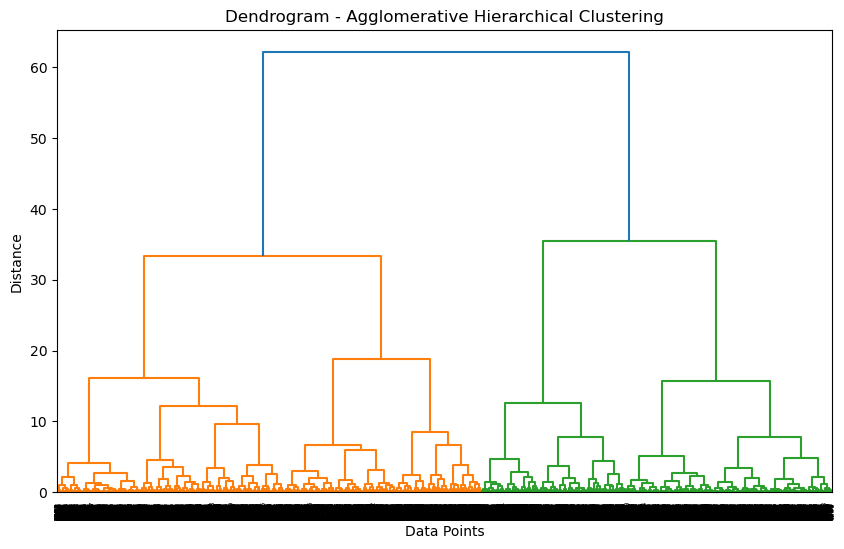

In [5]:
plt.figure(figsize=(10, 6))
plt.title('Dendrogram - Agglomerative Hierarchical Clustering')
Dendrogram = shc.dendrogram(shc.linkage(X_principal, method='ward'))
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()


### Step 6: Build Agglomerative Clustering models for k = 2, 3, 4, 5 and 6

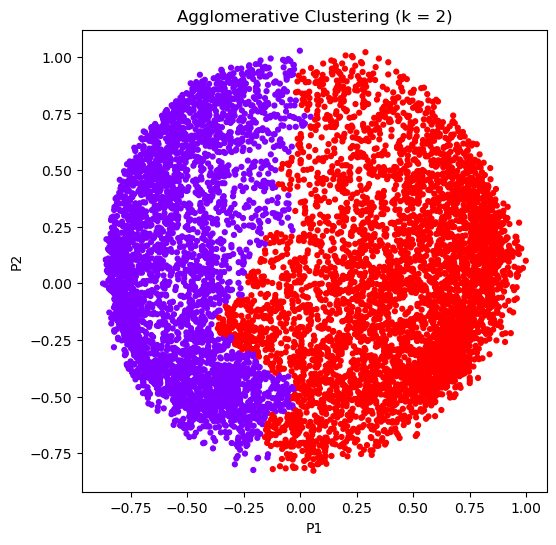

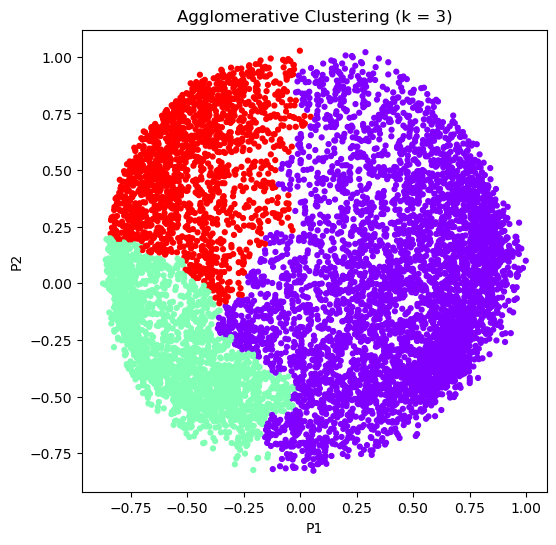

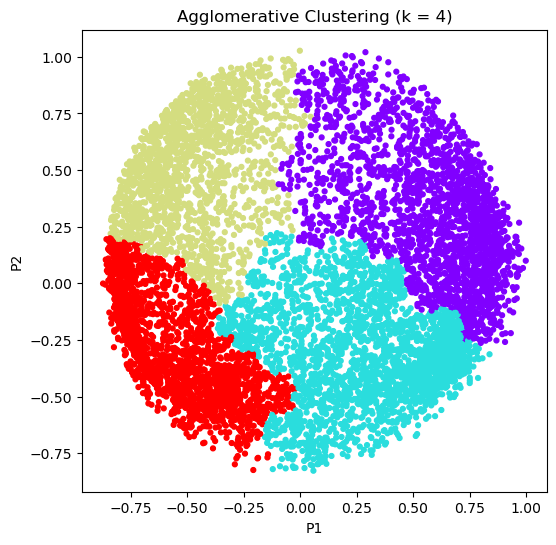

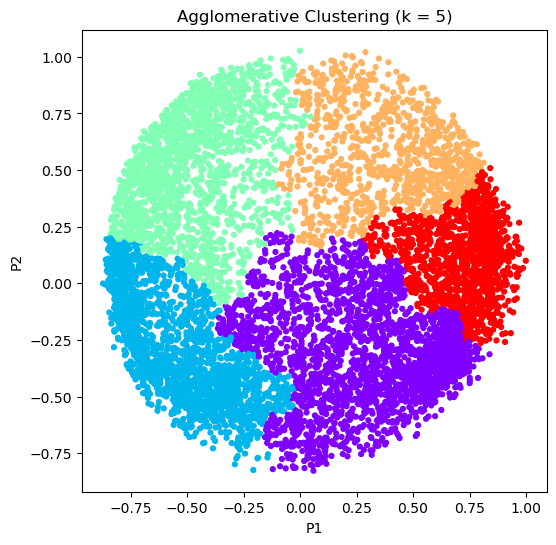

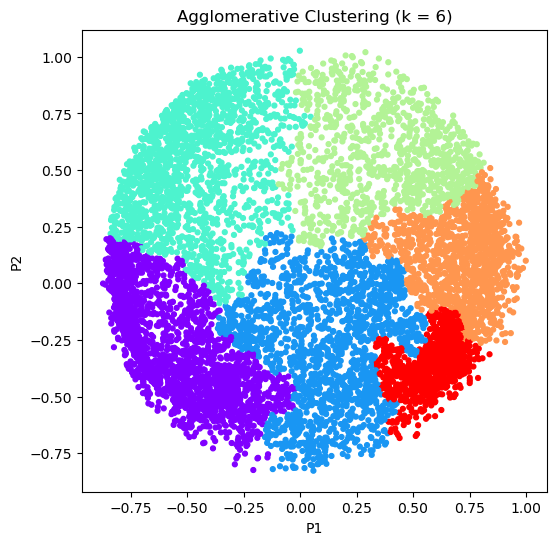

In [6]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []
cluster_labels = {}

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_principal)
    cluster_labels[k] = labels
    score = silhouette_score(X_principal, labels)
    silhouette_scores.append(score)

    plt.figure(figsize=(6, 6))
    plt.scatter(X_principal['P1'], X_principal['P2'], c=labels, cmap='rainbow', s=12)
    plt.title(f'Agglomerative Clustering (k = {k})')
    plt.xlabel('P1')
    plt.ylabel('P2')
    plt.show()


### Step 7: Evaluate models using Silhouette Score

,Number of Clusters (k),Silhouette Score
0,2,0.421321
1,3,0.400268
2,4,0.385217
3,5,0.356036
4,6,0.344937


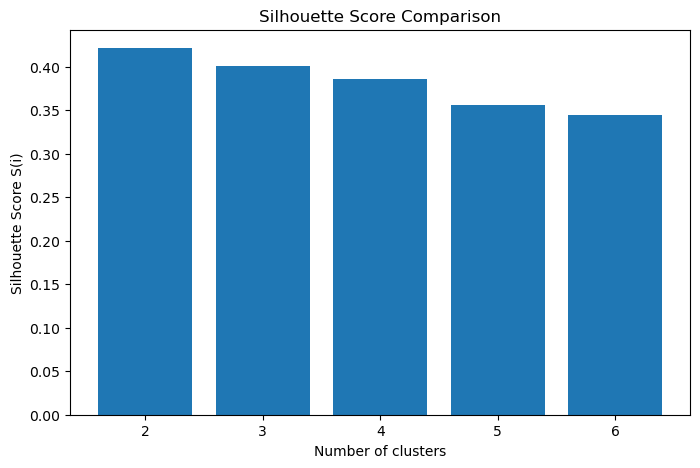

Optimal number of clusters: 2
Highest Silhouette Score: 0.4213


In [7]:
results = pd.DataFrame({
    'Number of Clusters (k)': k_values,
    'Silhouette Score': silhouette_scores
})

display(results)

plt.figure(figsize=(8, 5))
plt.bar(k_values, silhouette_scores)
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score S(i)')
plt.title('Silhouette Score Comparison')
plt.xticks(k_values)
plt.show()

optimal_k = k_values[int(np.argmax(silhouette_scores))]
best_score = max(silhouette_scores)
print('Optimal number of clusters:', optimal_k)
print('Highest Silhouette Score:', round(best_score, 4))


## Conclusion

Agglomerative hierarchical clustering was successfully implemented on the Credit Card Dataset. The data was cleaned, standardized, normalized and reduced to two principal components using PCA. A dendrogram was generated to visualize the hierarchical merging of clusters. Models with 2, 3, 4, 5 and 6 clusters were evaluated using Silhouette Score. The number of clusters having the highest Silhouette Score is selected as the optimal number of clusters for this implementation.